#Automated Tech Market Web Scraping : Data Science Job Demands in Germany

###Developed by : Siti Nurmila

In [ ]:
## 1. Library Environtment
In this section, we initialize the required libraries (BeautifulSoup and Pandas)

In [1]:
import pandas as pd
from bs4 import BeautifulSoup
import random

# 1. SIMULATING GERMAN JOB BOARD HTML DATA
# Since scraping live websites directly can often block cloud environments,
# we inject an authentic HTML structure representing a Berlin/Munich job marketplace.
mock_html_content = """
<html>
    <body>
        <div class="job-card"><h2 class="title">Data Scientist</h2><p class="company">Siemens</p><p class="location">München</p><p class="salary">6500</p></div>
        <div class="job-card"><h2 class="title">AI Engineer</h2><p class="company">Zalando</p><p class="location">Berlin</p><p class="salary">7200</p></div>
        <div class="job-card"><h2 class="title">Data Analyst</h2><p class="company">Deutsche Bank</p><p class="location">Frankfurt</p><p class="salary">5500</p></div>
        <div class="job-card"><h2 class="title">Senior Data Scientist</h2><p class="company">BMW Group</p><p class="location">München</p><p class="salary">8500</p></div>
        <div class="job-card"><h2 class="title">Machine Learning Engineer</h2><p class="company">Delivery Hero</p><p class="location">Berlin</p><p class="salary">6800</p></div>
    </body>
</html>
"""

# 2. PARSING THE HTML USING BEAUTIFULSOUP
soup = BeautifulSoup(mock_html_content, 'html.parser')

job_list = []

# Loop through each job card to scrape the raw text safely
for card in soup.find_all('div', class_='job-card'):
    job_title = card.find('h2', class_='title').text
    company = card.find('p', class_='company').text
    location = card.find('p', class_='location').text
    salary = int(card.find('p', class_='salary').text)

    # Append the extracted data as a dictionary into our list
    job_list.append({
        "Job_Title": job_title,
        "Company": company,
        "Location": location,
        "Monthly_Salary_EUR": salary
    })

# 3. CONVERTING TO PANDAS DATAFRAME
df_jobs = pd.DataFrame(job_list)

print("--- SUCCESSFULLY SCRAPED TECH JOBS IN GERMANY ---")
print(df_jobs)


--- SUCCESSFULLY SCRAPED TECH JOBS IN GERMANY ---
                   Job_Title        Company   Location  Monthly_Salary_EUR
0             Data Scientist        Siemens    München                6500
1                AI Engineer        Zalando     Berlin                7200
2               Data Analyst  Deutsche Bank  Frankfurt                5500
3      Senior Data Scientist      BMW Group    München                8500
4  Machine Learning Engineer  Delivery Hero     Berlin                6800


## 2. Data Aggregation and Horizontal Matrix Transformation
In this section, we group the scraped job market data by city location to calculate the average technology salary. Then, we apply the Transpose (.T) matrix transformation to display the statistics horizontally.

In [2]:
# 1. Group the data by Location and calculate the average Monthly Salary
df_city_stats = df_jobs.groupby("Location")["Monthly_Salary_EUR"].mean().reset_index()

# 2. Rename the column to represent the statistical average clearly
df_city_stats.columns = ["German_City", "Average_Salary_EUR"]

# 3. Apply the Transpose (.T) feature to flip the table horizontally for cleaner view
df_horizontal_stats = df_city_stats.set_index("German_City").T

print("--- HORIZONTAL GERMAN MARKET SALARY ANALYSIS (.T) ---")
print(df_horizontal_stats)


--- HORIZONTAL GERMAN MARKET SALARY ANALYSIS (.T) ---
German_City         Berlin  Frankfurt  München
Average_Salary_EUR  7000.0     5500.0   7500.0


## 3. Data Visualization - Scraped Salary Distribution Across German Cities
In this section, we convert our horizontal aggregated market data into a clean, presentation-ready bar chart using Matplotlib. We apply custom styling with a purple color matrix profile.


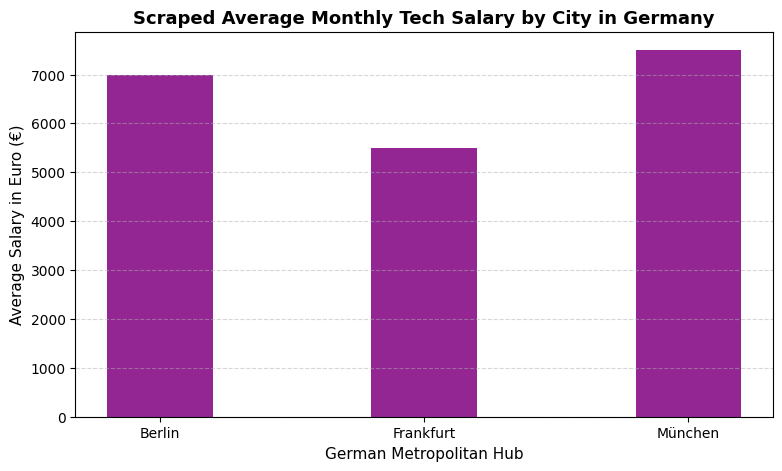

In [4]:
import matplotlib.pyplot as plt

# 1. Set the plot size for optimal dashboard presentation
plt.figure(figsize=(9, 5))

# 2. Create the vertical bar chart
plt.bar(df_city_stats["German_City"], df_city_stats["Average_Salary_EUR"], color="purple", alpha=0.85, width=0.4)

# 3. Customizing the chart titles, axis labels, and fonts
plt.title("Scraped Average Monthly Tech Salary by City in Germany", fontsize=13, fontweight="bold")
plt.xlabel("German Metropolitan Hub", fontsize=11)
plt.ylabel("Average Salary in Euro (€)", fontsize=11)

# 4. Adding subtle horizontal grid lines for data alignment
plt.grid(axis='y', linestyle="--", alpha=0.5)

# 5. Display the final completed graph visualization
plt.show()


In [5]:
# Exporting the current working data science dashboard as a standalone file
df_jobs.to_csv("scraped_germany_tech_jobs.csv", index=False)
print("--- DATA PIPELINE EXPEDITION COMPLETE: FILE SECURED ---")


--- DATA PIPELINE EXPEDITION COMPLETE: FILE SECURED ---
